# Residual Connection과 Gradient 소실 실습

문서 **「Residual Connection과 Gradient 소실: 처음부터 정리」**의 실습 노트북입니다. 위에서부터 차례로 실행하면 됩니다(CPU 약 15초).

| Part | 내용 | 문서 절 |
| --- | --- | --- |
| 0 | `∂L/∂x = Jᵀg` 검증, `nn.Linear` 저장 모양과 역전파 식 | 3, 4절 |
| 1 | 층별 activation gradient 크기 (5개 구조) | 1, 9절 |
| 2 | identity 경로 대 branch 경로 분해 | 8, 9절 |
| 3 | end-to-end Jacobian 특이값 스펙트럼 | 7절 |
| 4 | null space와 방향별 소실 장난감 예제 | 6, 7절 |
| 5 | Shattering: 가까운 입력끼리 gradient 방향이 닮았나 | 9절 |
| 6 | 학습 후 `‖∇W‖/‖W‖`와 lesion 실험 | 1, 9절 |
| 7 | 입력 공간 지형: 출력을 평면 위에 그려 shattering 보기 | 11절 |
| 8 | weight 공간 지형: 학습된 weight 주변 loss landscape | 11절 |

전체 실행은 CPU 기준 약 4분입니다(Part 8이 대부분).

필요 패키지: `pip install torch matplotlib`

## 공통 설정

폭 64짜리 residual stream을 50블록 쌓은 MLP로 실험합니다. 숫자를 바꿔 보면서 깊이와 폭이 결과에 어떤 영향을 주는지 확인해 보세요.

In [1]:
%matplotlib inline
import json
import os

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.func import jacrev

torch.manual_seed(0)
OUT = "outputs"
os.makedirs(OUT, exist_ok=True)

D = 64        # residual stream 폭
DEPTH = 50    # 블록 수
BATCH = 128

## 모델 정의

비교할 구조는 다섯 가지입니다. branch는 `F(h) = W2 · relu(W1 · h)`입니다.

| mode | 블록 | 비교 포인트 |
| --- | --- | --- |
| `plain` | `h ← relu(Wh)` | skip 없음, PyTorch 기본 초기화 |
| `plain_he` | `h ← relu(Wh)` | skip 없음, He 초기화로 **norm은 유지**되게 맞춤 |
| `residual` | `h ← h + F(h)` | 순수 residual, LayerNorm 없음 |
| `post_ln` | `h ← LN(h + F(h))` | LN이 덧셈 **뒤** → 항등 경로가 매 층 LN을 통과 |
| `pre_ln` | `h ← h + F(LN(h))` | LN이 branch **안** → 항등 경로가 순수한 `I` |

`Net.forward(x, log=dict)`로 부르면 각 블록 출력 `h_l`에 hook을 걸어 `∂L/∂h_l`(activation gradient)을 기록합니다.

In [2]:
class Block(nn.Module):
    """
    mode
      plain   : h ← relu(W h)                       (skip 없음, PyTorch 기본 초기화)
      plain_he: h ← relu(W h)                       (skip 없음, He 초기화로 norm은 유지되게)
      residual: h ← h + F(h)                        (LayerNorm 없음)
      post_ln : h ← LN(h + F(h))                    (원조 Transformer 방식)
      pre_ln  : h ← h + F(LN(h))                    (GPT-2 이후 표준)
    F(h) = W2 · relu(W1 · h)
    """

    def __init__(self, d, mode):
        super().__init__()
        self.mode = mode
        self.off = False  # Part 6 lesion: True면 branch를 끈다 (F = 0)
        if mode in ("plain", "plain_he"):
            self.lin = nn.Linear(d, d)
            if mode == "plain_he":
                nn.init.kaiming_normal_(self.lin.weight, nonlinearity="relu")
                nn.init.zeros_(self.lin.bias)
        else:
            self.f = nn.Sequential(nn.Linear(d, d), nn.ReLU(), nn.Linear(d, d))
            self.ln = nn.LayerNorm(d) if mode in ("post_ln", "pre_ln") else None

    def branch(self, h):
        """residual 계열에서 F 부분만 (Part 2 분해에 사용)"""
        if self.mode == "pre_ln":
            return self.f(self.ln(h))
        return self.f(h)

    def forward(self, h):
        if self.mode in ("plain", "plain_he"):
            return F.relu(self.lin(h))
        if self.off:  # lesion: h ← h (+ post_ln이면 LN만)
            return self.ln(h) if self.mode == "post_ln" else h
        if self.mode == "residual":
            return h + self.f(h)
        if self.mode == "post_ln":
            return self.ln(h + self.f(h))
        if self.mode == "pre_ln":
            return h + self.f(self.ln(h))
        raise ValueError(self.mode)


class Net(nn.Module):
    def __init__(self, d=D, depth=DEPTH, mode="residual"):
        super().__init__()
        self.mode = mode
        self.blocks = nn.ModuleList([Block(d, mode) for _ in range(depth)])
        self.head = nn.Linear(d, 1)
        self.final_ln = nn.LayerNorm(d) if mode == "pre_ln" else nn.Identity()

    def forward(self, x, log=None):
        """log가 dict이면 각 블록 출력 h_l에 hook을 걸어 ∂L/∂h_l을 기록"""
        h = x
        for i, blk in enumerate(self.blocks):
            h = blk(h)
            if log is not None and h.requires_grad:
                h.register_hook(lambda g, i=i: log.__setitem__(i, g.detach().clone()))
        return self.head(self.final_ln(h))


MODES = ["plain", "plain_he", "residual", "post_ln", "pre_ln"]


def make_data(n=BATCH, d=D, seed=1):
    g = torch.Generator().manual_seed(seed)
    x = torch.randn(n, d, generator=g)
    y = torch.randn(n, 1, generator=g)
    return x, y

## Part 0. 역전파 기초 검증

문서 3, 4절의 식을 autograd로 직접 확인합니다.

- (a) `y1 = x1·x2`, `y2 = x1 + 3·x2`에서 Jacobian을 구하고, `Jᵀg`(세로 표기)와 `gJ`(가로 표기)가 autograd 결과와 같은지, `Jg`(잘못된 배치)는 왜 다른지 봅니다.
- (b) `nn.Linear(4, 3)`의 `weight`가 `(3, 4)` = (out, in)으로 저장되는지, 그리고 `grad_x = G @ W`, `grad_W = G.T @ X`가 맞는지 확인합니다.

In [3]:
def part0():
    print("\n=== Part 0. 역전파 기초 검증 ===")

    # (a) 손으로 만든 함수: y1 = x1*x2, y2 = x1 + 3*x2
    x = torch.tensor([2.0, 5.0], requires_grad=True)
    f = lambda x: torch.stack([x[0] * x[1], x[0] + 3 * x[1]])
    J = jacrev(f)(x).detach()                 # 행 = 출력, 열 = 입력
    print("J =\n", J)                         # [[x2, x1], [1, 3]] = [[5, 2], [1, 3]]

    g = torch.tensor([1.0, 0.1])              # ∂L/∂y 를 (a, b) = (1, 0.1)로 가정
    y = f(x)
    (grad_x,) = torch.autograd.grad(y, x, grad_outputs=g)
    print("autograd ∂L/∂x  :", grad_x)
    print("Jᵀ · g (세로)    :", J.T @ g)
    print("g · J  (가로)    :", g @ J)        # 같은 숫자
    print("J · g  (틀린 배치):", J @ g)       # 행과 짝지어져서 다른 숫자

    # (b) nn.Linear의 저장 모양과 역전파 식
    layer = nn.Linear(4, 3)
    print("\nnn.Linear(4, 3).weight.shape =", tuple(layer.weight.shape), " ← (out, in)")
    X = torch.randn(5, 4, requires_grad=True)
    Y = layer(X)
    G = torch.randn_like(Y)                   # 임의의 upstream gradient
    Y.backward(G)
    W = layer.weight.detach()
    print("grad_x == G @ W        :", torch.allclose(X.grad, G @ W, atol=1e-6))
    print("grad_W == G.T @ X      :", torch.allclose(layer.weight.grad, G.T @ X.detach(), atol=1e-6))
    print("Linear의 Jacobian == W :", torch.allclose(jacrev(lambda v: layer(v))(X[0].detach()), W, atol=1e-6))

part0()


=== Part 0. 역전파 기초 검증 ===


J =
 tensor([[5., 2.],
        [1., 3.]])
autograd ∂L/∂x  : tensor([5.1000, 2.3000])
Jᵀ · g (세로)    : tensor([5.1000, 2.3000])
g · J  (가로)    : tensor([5.1000, 2.3000])
J · g  (틀린 배치): tensor([5.2000, 1.3000])

nn.Linear(4, 3).weight.shape = (3, 4)  ← (out, in)
grad_x == G @ W        : True
grad_W == G.T @ X      : True
Linear의 Jacobian == W : True


## Part 1. 층별 activation gradient 크기

각 블록 출력의 `∂L/∂h_l`을 RMS(`norm / sqrt(원소 수)`)로 재서 깊이에 대해 로그 스케일로 그립니다. **소실이면 입력 쪽(왼쪽)으로 갈수록 직선으로 떨어집니다.**

볼 것:
- `plain`은 입력 쪽이 출력 쪽의 약 10⁻¹⁹배로 떨어집니다.
- `plain_he`는 초기화 덕분에 norm은 평탄합니다. 그런데 Part 3, 5에서 이 구조가 방향 단위로는 망가져 있다는 게 드러납니다.
- `post_ln`은 원조 Transformer 구조라 대조군으로 넣었지만, 이 작은 MLP의 초기화 시점에서는 norm이 오히려 가장 평탄합니다. 논문에서 보고된 Post-LN의 불안정은 Transformer를 **학습하는 과정**에서 나타나는 문제라 이 설정으로는 재현되지 않습니다.


=== Part 1. 층별 activation gradient (RMS) ===
plain      첫 블록 2.62e-22 | 마지막 블록 1.08e-03 | 첫/마지막 = 2.42e-19
plain_he   첫 블록 5.90e-04 | 마지막 블록 1.06e-03 | 첫/마지막 = 5.56e-01
residual   첫 블록 1.24e-02 | 마지막 블록 3.03e-03 | 첫/마지막 = 4.11e+00
post_ln    첫 블록 1.35e-03 | 마지막 블록 1.34e-03 | 첫/마지막 = 1.00e+00


pre_ln     첫 블록 1.31e-03 | 마지막 블록 6.91e-04 | 첫/마지막 = 1.90e+00


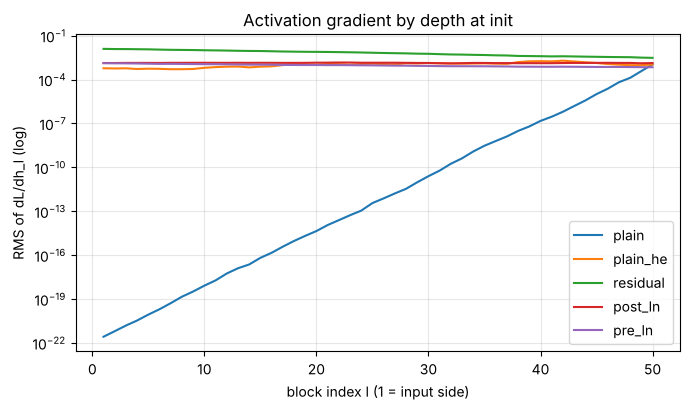

In [4]:
def grad_norms(model, x, y):
    log = {}
    model.zero_grad()
    loss = F.mse_loss(model(x, log=log), y)
    loss.backward()
    # 샘플당 RMS: 원소 수에 영향받지 않게 norm / sqrt(원소 수)
    return [log[i].pow(2).mean().sqrt().item() for i in range(len(model.blocks))]


def part1():
    print("\n=== Part 1. 층별 activation gradient (RMS) ===")
    x, y = make_data()
    results = {}
    for mode in MODES:
        torch.manual_seed(0)
        model = Net(mode=mode)
        norms = grad_norms(model, x, y)
        results[mode] = norms
        ratio = norms[0] / norms[-1]
        print(f"{mode:9s}  첫 블록 {norms[0]:.2e} | 마지막 블록 {norms[-1]:.2e} | 첫/마지막 = {ratio:.2e}")

    plt.figure(figsize=(7, 4.2))
    for mode, norms in results.items():
        plt.semilogy(range(1, DEPTH + 1), norms, label=mode)
    plt.xlabel("block index l (1 = input side)")
    plt.ylabel("RMS of dL/dh_l (log)")
    plt.title("Activation gradient by depth at init")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{OUT}/part1_grad_norm_by_depth.png", dpi=150)
    plt.show()
    return results

r1 = part1()

## Part 2. identity 대 branch 분해

residual 블록의 역전파는 두 항의 합입니다.

`∂L/∂h_l = g_{l+1}`(identity) `+ J_Fᵀ g_{l+1}`(branch)

블록마다 branch 항만 `torch.autograd.grad`로 따로 구해서 비교합니다.

- `‖branch‖/‖identity‖`가 1에 가깝고 cos ≈ −1이면 두 항이 **상쇄**되어 residual이 있어도 소실됩니다.
- 비율이 1보다 훨씬 작으면 branch가 거의 기여하지 않는 상태입니다.
- "이 블록 통과 배율"을 50블록 곱하면 Part 1의 첫/마지막 비율과 맞아야 합니다.

In [5]:
def part2(mode="residual"):
    """∂L/∂h_l = g_{l+1} (identity) + J_Fᵀ g_{l+1} (branch) 를 블록마다 분리"""
    print(f"\n=== Part 2. identity 대 branch 분해 ({mode}) ===")
    torch.manual_seed(0)
    model = Net(mode=mode)
    x, y = make_data()

    # 순전파하면서 각 블록의 입력 h_{l-1}을 저장, 출력 쪽 gradient는 hook으로
    inputs, log = [], {}
    h = x
    for i, blk in enumerate(model.blocks):
        inputs.append(h.detach())
        h = blk(h)
        h.register_hook(lambda g, i=i: log.__setitem__(i, g.detach()))
    F.mse_loss(model.head(model.final_ln(h)), y).backward()

    rows = []
    for i, blk in enumerate(model.blocks):
        h_in = inputs[i].clone().requires_grad_()
        g_out = log[i]                                     # ∂L/∂h_{l+1}
        (g_branch,) = torch.autograd.grad(blk.branch(h_in), h_in, grad_outputs=g_out)
        ratio = (g_branch.norm() / g_out.norm()).item()
        cos = F.cosine_similarity(g_branch.flatten(), g_out.flatten(), dim=0).item()
        total = ((g_out + g_branch).norm() / g_out.norm()).item()
        rows.append({"block": i + 1, "branch/identity": ratio, "cos": cos, "total_gain": total})

    for r in rows[:: max(1, DEPTH // 10)]:
        print(f"block {r['block']:2d}: ‖branch‖/‖identity‖ = {r['branch/identity']:.3f}, "
              f"cos = {r['cos']:+.3f}, 이 블록 통과 배율 = {r['total_gain']:.3f}")
    prod = 1.0
    for r in rows:
        prod *= r["total_gain"]
    print(f"블록 통과 배율의 곱 (end-to-end 근사) = {prod:.3f}")
    print("해석: cos ≈ -1 & 비율 ≈ 1 → 상쇄(소실), 비율 ≪ 1 → branch가 거의 기여 안 함")
    return rows

r2 = part2("residual")
r2b = part2("post_ln")


=== Part 2. identity 대 branch 분해 (residual) ===
block  1: ‖branch‖/‖identity‖ = 0.232, cos = +0.066, 이 블록 통과 배율 = 1.041
block  6: ‖branch‖/‖identity‖ = 0.224, cos = +0.089, 이 블록 통과 배율 = 1.044
block 11: ‖branch‖/‖identity‖ = 0.245, cos = -0.029, 이 블록 통과 배율 = 1.023
block 16: ‖branch‖/‖identity‖ = 0.235, cos = +0.041, 이 블록 통과 배율 = 1.037
block 21: ‖branch‖/‖identity‖ = 0.243, cos = -0.054, 이 블록 통과 배율 = 1.016
block 26: ‖branch‖/‖identity‖ = 0.236, cos = +0.056, 이 블록 통과 배율 = 1.040
block 31: ‖branch‖/‖identity‖ = 0.246, cos = +0.123, 이 블록 통과 배율 = 1.059
block 36: ‖branch‖/‖identity‖ = 0.254, cos = +0.071, 이 블록 통과 배율 = 1.049
block 41: ‖branch‖/‖identity‖ = 0.276, cos = -0.018, 이 블록 통과 배율 = 1.032
block 46: ‖branch‖/‖identity‖ = 0.228, cos = +0.011, 이 블록 통과 배율 = 1.028
블록 통과 배율의 곱 (end-to-end 근사) = 4.282
해석: cos ≈ -1 & 비율 ≈ 1 → 상쇄(소실), 비율 ≪ 1 → branch가 거의 기여 안 함

=== Part 2. identity 대 branch 분해 (post_ln) ===
block  1: ‖branch‖/‖identity‖ = 0.221, cos = +0.021, 이 블록 통과 배율 = 1.029
block  6: ‖branc

## Part 3. Jacobian 특이값 스펙트럼

샘플 하나에 대해 end-to-end Jacobian `∂h_L/∂h_0`(64×64)를 직접 구하고 특이값을 봅니다. 특이값은 **방향별로 gradient가 몇 배가 되는지**입니다. 1 근처에 모여 있으면 건강하고, 0.01보다 작은 방향은 사실상 죽은 방향입니다.

볼 것:
- `plain_he`: Part 1에서 norm은 멀쩡했는데, 64개 방향 중 대부분이 죽어 있습니다. **norm만 보면 놓치는 경우**입니다.
- `post_ln`: 죽은 방향이 정확히 2개입니다. LayerNorm 출력은 항상 평균 0, 크기 일정이라 평균 방향 (1, 1, …, 1)과 크기 방향(출력 자신)으로는 움직일 수 없기 때문입니다.

마지막의 VJP 근사는 큰 모델처럼 Jacobian 전체를 만들 수 없을 때 쓰는 방법입니다. 랜덤 벡터 `v`로 `‖Jᵀv‖/‖v‖`의 분포를 봅니다.


=== Part 3. end-to-end Jacobian 특이값 ===


plain      최대 7.17e-19 | 중앙값 8.89e-27 | 최소 0.00e+00 | 0.01 미만 방향 64/64
plain_he   최대 1.23e+00 | 중앙값 2.11e-08 | 최소 0.00e+00 | 0.01 미만 방향 59/64
residual   최대 1.50e+01 | 중앙값 1.01e+00 | 최소 6.62e-02 | 0.01 미만 방향 0/64
post_ln    최대 4.65e+00 | 중앙값 3.49e-01 | 최소 4.07e-08 | 0.01 미만 방향 2/64
pre_ln     최대 6.19e+00 | 중앙값 1.03e+00 | 최소 1.72e-01 | 0.01 미만 방향 0/64


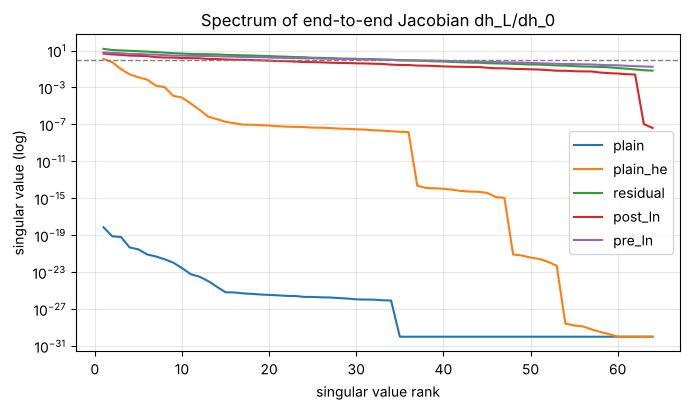

[VJP 근사, pre_ln] ‖Jᵀv‖/‖v‖ 평균 2.019, 표준편차 0.321
해석: plain_he는 Part 1의 norm은 멀쩡한데 64개 방향 중 대부분이 죽어 있다.
      post_ln의 죽은 방향 2개는 LayerNorm의 '평균 방향'(1,1,…,1)과 '크기 방향'(출력 자신)이다.
      LN 출력은 항상 평균 0, 크기 일정이라 그 두 방향으로는 움직일 수 없고,
      역전파에서도 그 두 방향 성분의 gradient는 0이 된다.


In [6]:
def end_to_end_jacobian(model, x0):
    """h_L = blocks(h_0) 의 Jacobian ∂h_L/∂h_0 (샘플 하나, D×D)"""

    def f(h):
        for blk in model.blocks:
            h = blk(h)
        return h

    return jacrev(f)(x0)


def part3():
    print("\n=== Part 3. end-to-end Jacobian 특이값 ===")
    x, _ = make_data(n=1)
    spectra = {}
    plt.figure(figsize=(7, 4.2))
    for mode in MODES:
        torch.manual_seed(0)
        model = Net(mode=mode)
        J = end_to_end_jacobian(model, x[0]).detach()
        s = torch.linalg.svdvals(J)
        spectra[mode] = s.tolist()
        print(f"{mode:9s}  최대 {s.max():.2e} | 중앙값 {s.median():.2e} | 최소 {s.min():.2e} | "
              f"0.01 미만 방향 {int((s < 0.01).sum())}/{len(s)}")
        plt.semilogy(range(1, len(s) + 1), s.clamp_min(1e-30), label=mode)  # 정확히 0인 값만 1e-30으로 표시
    plt.axhline(1.0, color="gray", ls="--", lw=1)
    plt.xlabel("singular value rank")
    plt.ylabel("singular value (log)")
    plt.title("Spectrum of end-to-end Jacobian dh_L/dh_0")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{OUT}/part3_jacobian_spectrum.png", dpi=150)
    plt.show()

    # 큰 모델에서 쓰는 근사: 랜덤 벡터 v에 대해 ‖Jᵀv‖/‖v‖ (전체 Jacobian 없이 VJP만)
    torch.manual_seed(0)
    model = Net(mode="pre_ln")
    h0 = x[0].clone().requires_grad_()
    h = h0
    for blk in model.blocks:
        h = blk(h)
    gains = []
    for _ in range(32):
        v = torch.randn_like(h)
        (u,) = torch.autograd.grad(h, h0, grad_outputs=v, retain_graph=True)
        gains.append((u.norm() / v.norm()).item())
    t = torch.tensor(gains)
    print(f"[VJP 근사, pre_ln] ‖Jᵀv‖/‖v‖ 평균 {t.mean():.3f}, 표준편차 {t.std():.3f}")
    print("해석: plain_he는 Part 1의 norm은 멀쩡한데 64개 방향 중 대부분이 죽어 있다.\n"
          "      post_ln의 죽은 방향 2개는 LayerNorm의 '평균 방향'(1,1,…,1)과 '크기 방향'(출력 자신)이다.\n"
          "      LN 출력은 항상 평균 0, 크기 일정이라 그 두 방향으로는 움직일 수 없고,\n"
          "      역전파에서도 그 두 방향 성분의 gradient는 0이 된다.")
    return spectra

r3 = part3()

## Part 4. null space와 방향별 소실

문서 6, 7절의 장난감 예제입니다.

- (a) `y = x1 + x2`에서 `(1, −1)` 방향은 출력을 바꾸지 않습니다(null space). 그래서 upstream gradient가 무엇이든 `∂L/∂x`에 그 방향 성분이 0입니다.
- (b) `diag(1, 0.1)`을 10번 통과하면 두 번째 방향은 10⁻¹⁰배로 소실되지만, 첫 번째 방향이 살아 있어 norm은 별로 안 줄어 보입니다.

In [7]:
def part4():
    print("\n=== Part 4. null space와 방향별 소실 ===")
    # (a) y = x1 + x2 : (1, -1) 방향은 출력에 영향이 없음 → gradient에도 그 성분이 없음
    W = torch.tensor([[1.0, 1.0]])
    for g in [torch.tensor([0.7]), torch.tensor([-2.0])]:
        grad_x = W.T @ g
        along_null = grad_x @ torch.tensor([1.0, -1.0]) / 2**0.5
        print(f"g = {g.item():+.1f} → ∂L/∂x = {grad_x.tolist()}, (1,-1) 방향 성분 = {along_null.item():.1f}")
    print("svdvals([1, 1]) =", torch.linalg.svdvals(W).tolist(), " (≈ √2, 나머지 방향은 null space)")

    # (b) diag(1, 0.1)을 10번 통과: norm은 그대로인데 두 번째 방향은 1e-10배
    A = torch.diag(torch.tensor([1.0, 0.1]))
    g = torch.tensor([1.0, 1.0])
    for _ in range(10):
        g = A.T @ g
    print(f"diag(1, 0.1)ᵀ 를 10번 곱한 gradient = {g.tolist()}")
    print(f"norm은 {torch.tensor([1.,1.]).norm():.3f} → {g.norm():.3f} (덜 줄어 보임), "
          f"두 번째 방향은 1e-10배로 소실")

part4()


=== Part 4. null space와 방향별 소실 ===
g = +0.7 → ∂L/∂x = [0.699999988079071, 0.699999988079071], (1,-1) 방향 성분 = 0.0
g = -2.0 → ∂L/∂x = [-2.0, -2.0], (1,-1) 방향 성분 = 0.0
svdvals([1, 1]) = [1.4142135381698608]  (≈ √2, 나머지 방향은 null space)
diag(1, 0.1)ᵀ 를 10번 곱한 gradient = [1.0, 1.0000002215182491e-10]
norm은 1.414 → 1.000 (덜 줄어 보임), 두 번째 방향은 1e-10배로 소실


## Part 5. Shattering

입력 공간의 한 직선 위에 256개 점을 찍고, 각 점에서 `∂output/∂x`를 구해 **이웃한 점끼리 gradient 방향이 얼마나 닮았는지**(cosine)를 봅니다. 크기가 아니라 방향(질)을 보는 지표입니다.

- 이웃 간 cos가 1에서 멀어질수록 gradient가 노이즈처럼 산산조각 난 상태입니다(Balduzzi et al., 2017).
- `plain`은 크기가 이미 10⁻¹⁹ 수준으로 소실돼서 이 지표가 의미 없습니다.
- `plain_he`는 norm은 유지되는데 방향이 망가집니다.

In [8]:
def part5():
    """
    입력 공간의 한 직선 위 점들에서 ∂output/∂x를 구하고,
    이웃한 점끼리 gradient가 얼마나 닮았는지(cosine) 본다.
    Balduzzi et al. (2017): skip 없는 깊은 망은 이웃끼리도 gradient가 거의 무관(백색잡음)해진다.
    """
    print("\n=== Part 5. Shattering (이웃 입력 간 gradient 유사도) ===")
    n = 256
    a, b = torch.randn(D), torch.randn(D)
    t = torch.linspace(-1, 1, n).unsqueeze(1)
    xs = a + t * b                                   # 직선 위의 n개 점
    out = {}
    for mode in MODES:
        torch.manual_seed(0)
        model = Net(mode=mode)
        x = xs.clone().requires_grad_()
        model(x).sum().backward()
        g = x.grad.double()
        g = g / g.norm(dim=1, keepdim=True).clamp_min(1e-300)  # 크기가 1e-19여도 방향만 비교
        cos_nb = (g[:-1] * g[1:]).sum(1).mean().item()
        cos_far = (g[: n // 2] * g[n // 2 :]).sum(1).mean().item()
        out[mode] = {"neighbor_cos": cos_nb, "far_cos": cos_far}
        print(f"{mode:9s}  이웃 간 cos = {cos_nb:.3f} | 멀리 떨어진 점 간 cos = {cos_far:.3f}")
    print("해석: 이웃 간 cos가 1에서 멀어질수록 gradient가 노이즈처럼 '산산조각' 난 상태.\n"
          "      plain은 gradient 크기가 1e-19 수준으로 이미 소실돼서 방향 비교가 의미 없음.\n"
          "      plain_he는 norm은 유지되는데(Part 1) 방향이 산산조각 난다 → norm만 보면 놓치는 경우")
    return out

r5 = part5()


=== Part 5. Shattering (이웃 입력 간 gradient 유사도) ===
plain      이웃 간 cos = 0.994 | 멀리 떨어진 점 간 cos = 0.168
plain_he   이웃 간 cos = 0.722 | 멀리 떨어진 점 간 cos = -0.010
residual   이웃 간 cos = 0.994 | 멀리 떨어진 점 간 cos = 0.429
post_ln    이웃 간 cos = 0.994 | 멀리 떨어진 점 간 cos = 0.422
pre_ln     이웃 간 cos = 0.998 | 멀리 떨어진 점 간 cos = 0.729
해석: 이웃 간 cos가 1에서 멀어질수록 gradient가 노이즈처럼 '산산조각' 난 상태.
      plain은 gradient 크기가 1e-19 수준으로 이미 소실돼서 방향 비교가 의미 없음.
      plain_he는 norm은 유지되는데(Part 1) 방향이 산산조각 난다 → norm만 보면 놓치는 경우


## Part 6. 학습 후 weight gradient 비율과 lesion

`pre_ln` 모델을 랜덤 teacher 네트워크에 맞춰 300 step 학습한 뒤 두 가지를 봅니다.

- (a) **`‖∇W‖/‖W‖`**: 앞쪽과 뒤쪽 블록의 상대 업데이트 크기가 비슷하면 앞쪽 층도 제대로 학습되고 있다는 뜻입니다.
- (b) **Lesion**: 블록 하나의 branch를 끄고(`F = 0`) loss가 얼마나 오르는지 봅니다. 하나를 꺼도 "평균만 예측하는 망가진 수준"에 한참 못 미치면, 깊은 한 경로가 아니라 짧은 경로들의 앙상블처럼 동작한다는 뜻입니다(Veit et al., 2016).

`mode`나 `steps`를 바꿔서 다른 구조와 비교해 보세요.


=== Part 6. 학습 후 weight gradient 비율과 lesion (pre_ln) ===


300 step 학습 후 전체 loss = 0.0013
‖∇W‖/‖W‖  앞 5개 블록: ['1.0e-03', '8.0e-04', '1.0e-03', '8.1e-04', '9.1e-04']
‖∇W‖/‖W‖  뒤 5개 블록: ['8.6e-04', '1.4e-03', '1.3e-03', '1.4e-03', '1.6e-03']


블록 하나를 껐을 때 loss 증가, 가장 큰 5개: [(1, 0.0039), (3, 0.0031), (48, 0.003), (24, 0.0026), (5, 0.0022)]
평균 증가 0.0008 (학습된 loss 0.0013, 평균만 예측하는 '망가진' 수준 0.0738)
가장 중요한 블록을 꺼도 loss 0.0052 → 망가진 수준의 7.0%
해석: 하나 꺼도 망가진 수준에 한참 못 미치면, 깊은 한 경로가 아니라 짧은 경로들의 앙상블처럼 동작 (Veit et al., 2016)


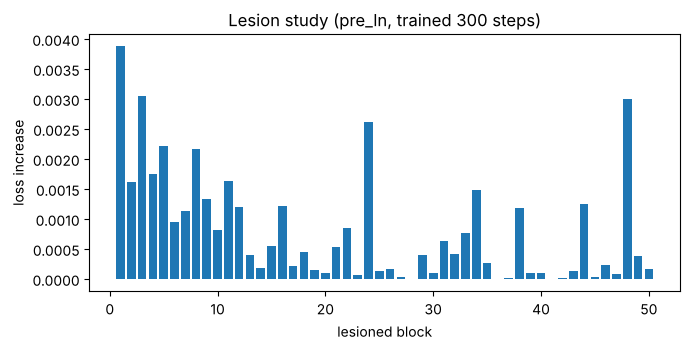

In [9]:
def part6(mode="pre_ln", steps=300):
    print(f"\n=== Part 6. 학습 후 weight gradient 비율과 lesion ({mode}) ===")
    torch.manual_seed(0)
    # 학습할 만한 목표: 랜덤 teacher 네트워크의 출력
    teacher = nn.Sequential(nn.Linear(D, 128), nn.Tanh(), nn.Linear(128, 1))
    X = torch.randn(2048, D)
    with torch.no_grad():
        Y = teacher(X)

    model = Net(mode=mode)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    for step in range(steps):
        idx = torch.randint(0, len(X), (BATCH,))
        loss = F.mse_loss(model(X[idx]), Y[idx])
        opt.zero_grad()
        loss.backward()
        opt.step()
    with torch.no_grad():
        base = F.mse_loss(model(X), Y).item()
    print(f"{steps} step 학습 후 전체 loss = {base:.4f}")

    # (a) weight gradient 상대 크기 ‖∇W‖/‖W‖ (블록 첫 Linear 기준)
    opt.zero_grad()
    F.mse_loss(model(X[:BATCH]), Y[:BATCH]).backward()
    ratios = [(b.f[0].weight.grad.norm() / b.f[0].weight.norm()).item() for b in model.blocks]
    print("‖∇W‖/‖W‖  앞 5개 블록:", [f"{r:.1e}" for r in ratios[:5]])
    print("‖∇W‖/‖W‖  뒤 5개 블록:", [f"{r:.1e}" for r in ratios[-5:]])

    # (b) lesion: 블록 하나의 branch를 끄고(F=0) loss가 얼마나 오르나
    increases = []
    for blk in model.blocks:
        blk.off = True
        with torch.no_grad():
            l = F.mse_loss(model(X), Y).item()
        blk.off = False
        increases.append(l - base)
    worst = sorted(range(DEPTH), key=lambda i: -increases[i])[:5]
    print("블록 하나를 껐을 때 loss 증가, 가장 큰 5개:",
          [(i + 1, round(increases[i], 4)) for i in worst])
    worst_loss = base + max(increases)
    print(f"평균 증가 {sum(increases) / DEPTH:.4f} (학습된 loss {base:.4f}, "
          f"평균만 예측하는 '망가진' 수준 {Y.var().item():.4f})")
    print(f"가장 중요한 블록을 꺼도 loss {worst_loss:.4f} → 망가진 수준의 {worst_loss / Y.var().item():.1%}")
    print("해석: 하나 꺼도 망가진 수준에 한참 못 미치면, 깊은 한 경로가 아니라 "
          "짧은 경로들의 앙상블처럼 동작 (Veit et al., 2016)")

    plt.figure(figsize=(7, 3.6))
    plt.bar(range(1, DEPTH + 1), increases)
    plt.xlabel("lesioned block")
    plt.ylabel("loss increase")
    plt.title(f"Lesion study ({mode}, trained {steps} steps)")
    plt.tight_layout()
    plt.savefig(f"{OUT}/part6_lesion.png", dpi=150)
    plt.show()
    return {"base_loss": base, "grad_ratio": ratios, "lesion_increase": increases}

r6 = part6()

## Part 7. 입력 공간 지형 (shattering을 눈으로 보기)

입력은 64차원이라 그대로 못 그리니까, 입력 공간에 평면 하나를 잘라냅니다.

`x(s, t) = x0 + s·d1 + t·d2`   (s, t ∈ [−1, 1])

기준 입력 x0에서 랜덤 방향 d1, d2로 뻗은 평면이고, 점마다 **출력 f(x)**를 높이로 그립니다. weight는 고정이고 움직이는 건 입력뿐입니다.

- 위치를 옮기는 것 = 다른 샘플로 바꾸는 것
- 그 지점의 기울기 = 입력에 대한 gradient `∂f/∂x`

높이를 loss가 아니라 출력으로 잡는 이유: MSE면 `∂L/∂x = (f − y) × ∂f/∂x`라서 앞의 스칼라는 크기와 부호만 바꾸고 방향은 `∂f/∂x`가 정합니다. 평면 위 인공 입력에는 정답도 없고요.

볼 것: 아랫줄 그래프(빨간 선을 따라간 기울기)가 plain_he는 백색잡음처럼 튀고, residual 계열은 큰 흐름이 보입니다.

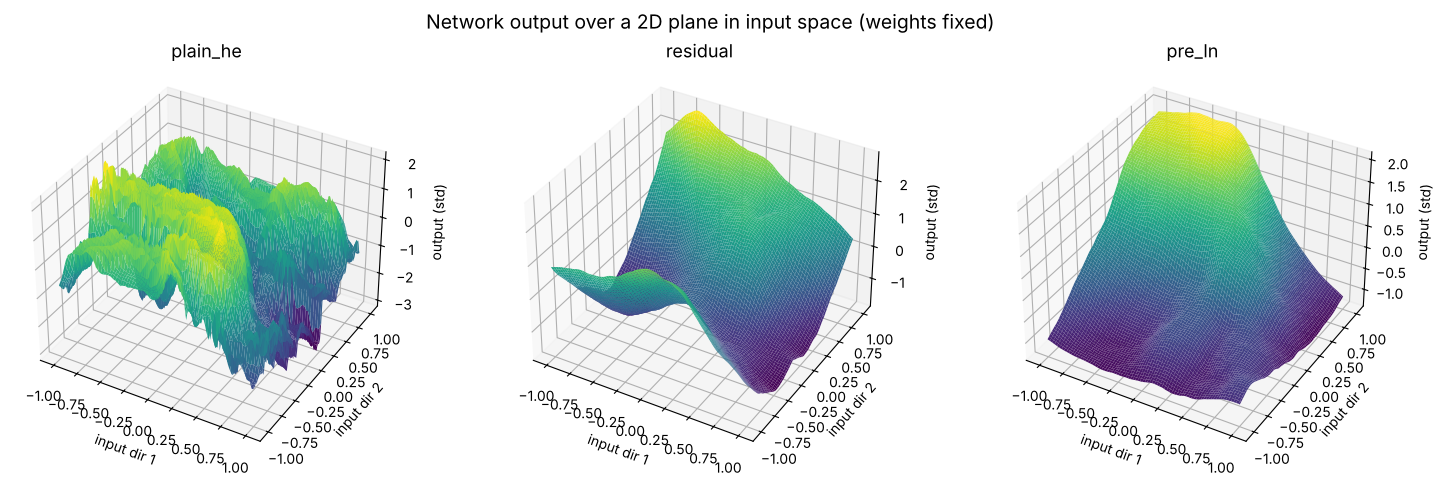

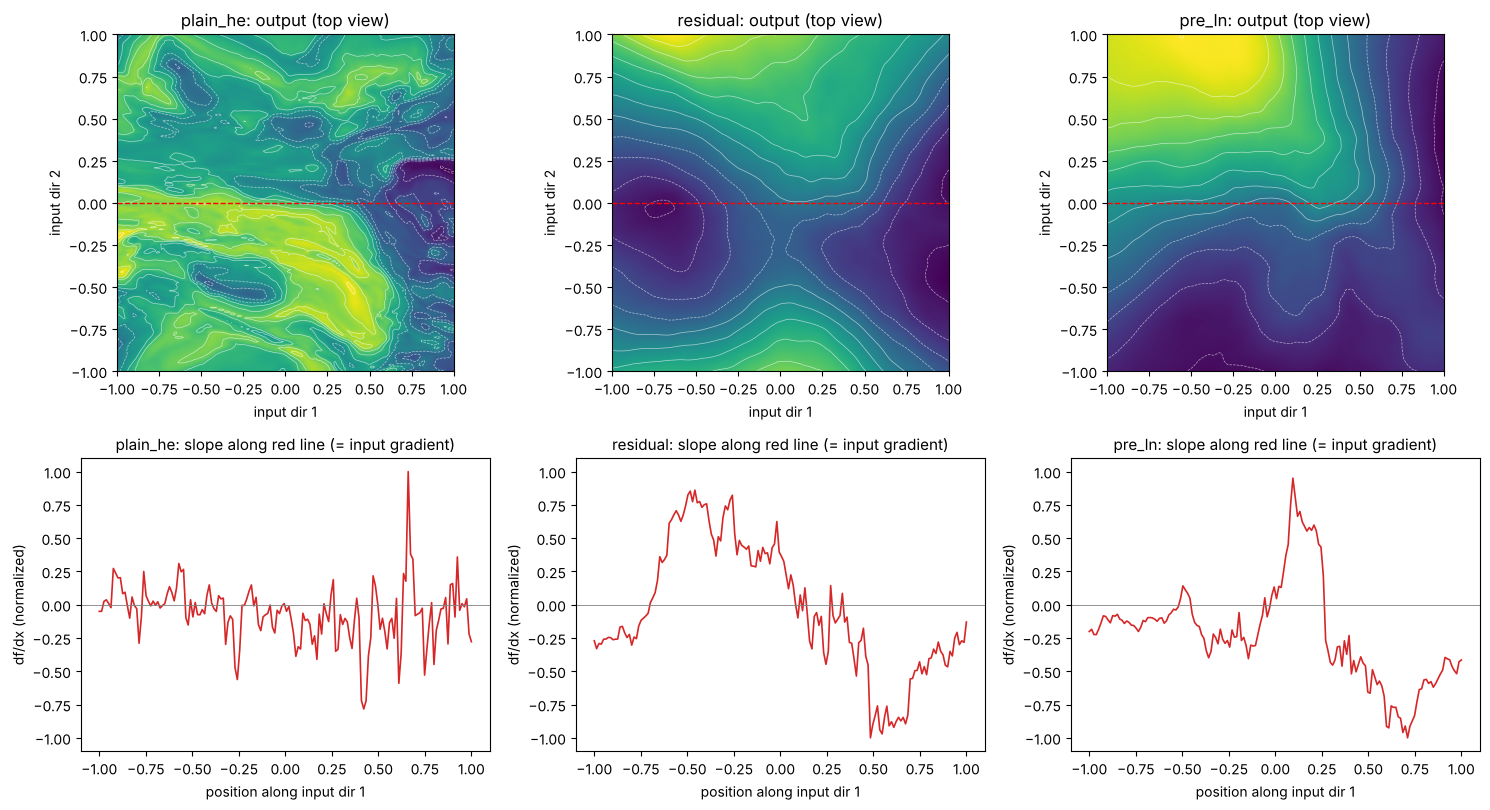

In [10]:
def part7(modes=("plain_he", "residual", "pre_ln"), n=160):
    g = torch.Generator().manual_seed(7)
    x0 = torch.randn(D, generator=g)
    d1 = torch.randn(D, generator=g); d1 = d1 / d1.norm() * x0.norm()
    d2 = torch.randn(D, generator=g); d2 = d2 / d2.norm() * x0.norm()
    s = torch.linspace(-1, 1, n)
    S, T = torch.meshgrid(s, s, indexing="ij")
    Xp = x0 + S.reshape(-1, 1) * d1 + T.reshape(-1, 1) * d2      # 평면 위 n*n개 입력

    surfaces, slopes = {}, {}
    for mode in modes:
        torch.manual_seed(0)
        model = Net(mode=mode)
        with torch.no_grad():
            f = model(Xp).reshape(n, n)
        surfaces[mode] = ((f - f.mean()) / f.std()).numpy()     # 구조끼리 비교하려고 높이 표준화

        # t = 0 직선 위에서 기울기 = 입력 gradient의 d1 성분
        xs = (x0 + s.reshape(-1, 1) * d1).clone().requires_grad_()
        model(xs).sum().backward()
        sl = (xs.grad @ d1 / d1.norm()).detach().numpy()
        slopes[mode] = sl / abs(sl).max()

    # 3D 지형
    fig = plt.figure(figsize=(15, 4.8))
    for k, mode in enumerate(modes):
        ax = fig.add_subplot(1, len(modes), k + 1, projection="3d")
        ax.plot_surface(S.numpy(), T.numpy(), surfaces[mode], cmap="viridis",
                        rstride=2, cstride=2, linewidth=0, antialiased=True)
        ax.set_title(mode, fontsize=13)
        ax.set_xlabel("input dir 1"); ax.set_ylabel("input dir 2"); ax.set_zlabel("output (std)")
        ax.view_init(elev=35, azim=-60)
    fig.suptitle("Network output over a 2D plane in input space (weights fixed)", fontsize=14)
    plt.tight_layout()
    plt.savefig(f"{OUT}/shattering_3d.png", dpi=130)
    plt.show()

    # 위에서 본 등고선 + 빨간 선을 따라간 기울기
    fig, axes = plt.subplots(2, len(modes), figsize=(15, 8.2), gridspec_kw={"height_ratios": [1.15, 1]})
    for k, mode in enumerate(modes):
        ax = axes[0, k]
        ax.imshow(surfaces[mode].T, origin="lower", extent=[-1, 1, -1, 1], cmap="viridis")
        ax.contour(S.numpy(), T.numpy(), surfaces[mode], levels=12, colors="white", linewidths=0.5, alpha=0.6)
        ax.axhline(0, color="red", lw=1, ls="--")
        ax.set_title(f"{mode}: output (top view)", fontsize=12)
        ax.set_xlabel("input dir 1"); ax.set_ylabel("input dir 2")
        ax = axes[1, k]
        ax.plot(s.numpy(), slopes[mode], color="C3", lw=1.2)
        ax.axhline(0, color="gray", lw=0.6)
        ax.set_ylim(-1.1, 1.1)
        ax.set_title(f"{mode}: slope along red line (= input gradient)", fontsize=11)
        ax.set_xlabel("position along input dir 1"); ax.set_ylabel("df/dx (normalized)")
    plt.tight_layout()
    plt.savefig(f"{OUT}/shattering_topview_and_slope.png", dpi=130)
    plt.show()


part7()

## Part 8. weight 공간 지형 (loss landscape)

Part 7과 반대로 **데이터를 고정하고 weight를 움직입니다**(Li et al., NeurIPS 2018 방식).

1. 세 구조를 같은 회귀 문제(Part 6의 teacher 흉내내기)로 500 step 학습해서 weight θ*를 얻습니다.
2. weight 공간의 랜덤 방향 d1, d2로 평면 `θ* + α·d1 + β·d2`를 잡고, 점마다 데이터 2048개에 대한 loss를 계산합니다.

랜덤 방향의 각 행(뉴런 하나)은 그 뉴런 실제 weight의 크기에 맞춥니다(filter normalization의 MLP판). 그래서 α = 1은 "모든 뉴런을 자기 크기만큼 흔든다"는 뜻이 됩니다. bias와 LayerNorm 파라미터는 움직이지 않습니다.

볼 것:
- 넓은 범위(±1): 모양보다 **폭발 규모**가 다릅니다. skip이 없으면 weight 변화가 50층에서 곱해져 loss가 10²² 수준까지 커지고, pre_ln은 LayerNorm이 크기를 되돌려 거의 안 커집니다.
- 확대(±0.15): 세 구조 모두 매끈한 그릇입니다. Li et al.이 보인 "skip 없는 망의 혼돈스러운 지형"은 이 장난감 설정(폭 64 MLP, 쉬운 회귀, Adam)에서는 재현되지 않습니다.

이 셀은 CPU에서 3분 정도 걸립니다. `n`을 줄이면 빨라집니다.


=== Part 8. weight 공간 loss 지형 ===


span ±1     plain_he  학습된 지점 loss 0.0008 | 평면 위 최대 2.5e+22 | 중앙값 6.09e+07
span ±1     residual  학습된 지점 loss 0.0012 | 평면 위 최대 2.12e+08 | 중앙값 139
span ±1     pre_ln    학습된 지점 loss 0.0005 | 평면 위 최대 1.18 | 중앙값 0.14


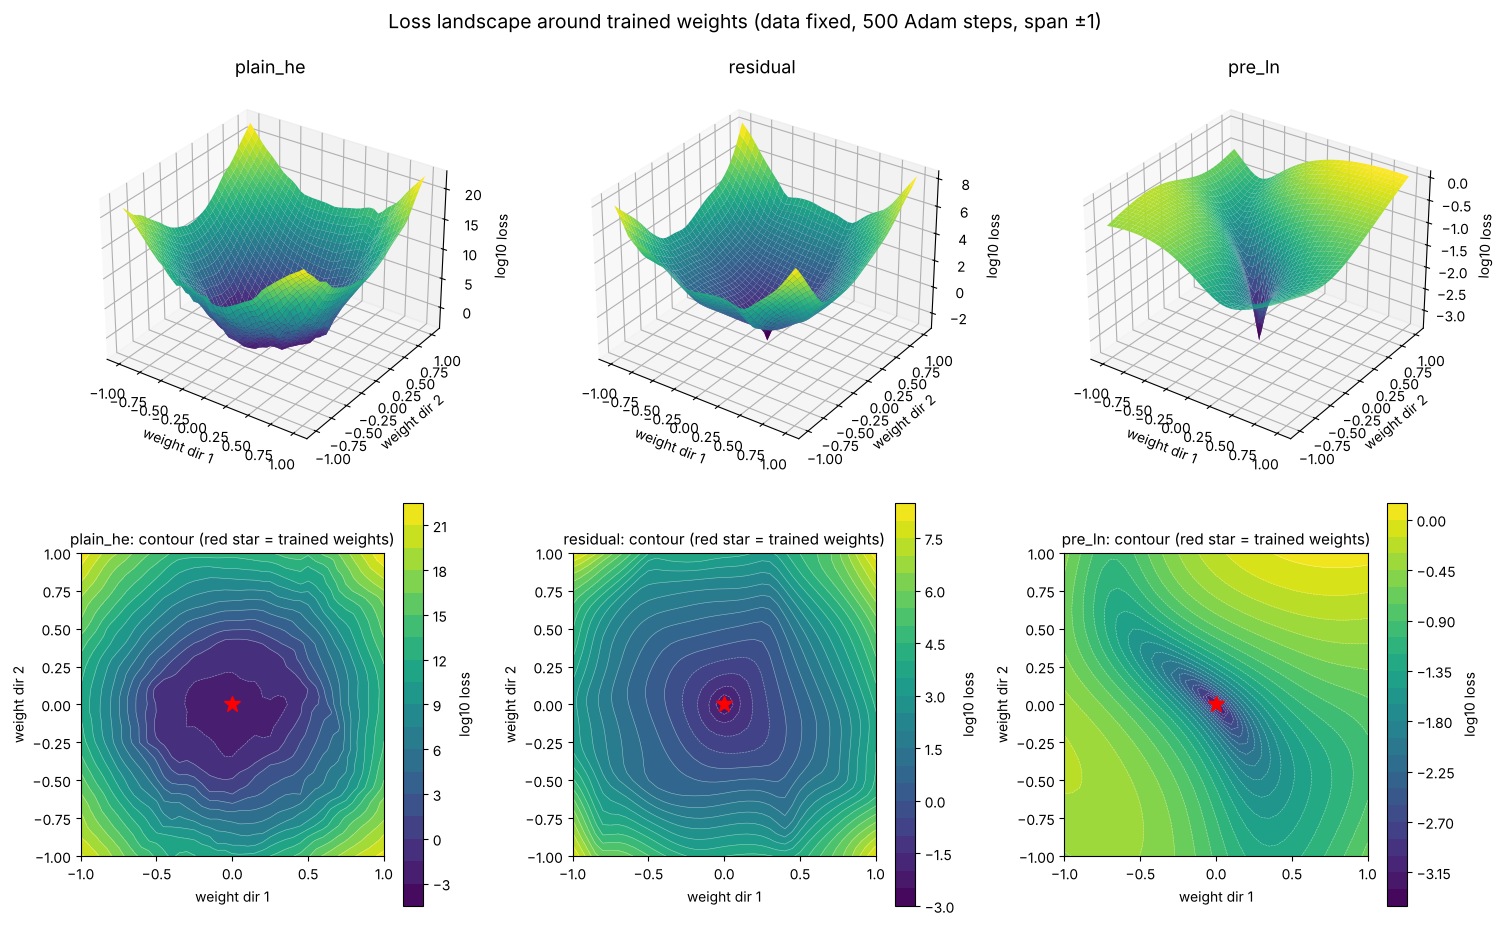

span ±0.15  plain_he  학습된 지점 loss 0.0008 | 평면 위 최대 0.032 | 중앙값 0.00832
span ±0.15  residual  학습된 지점 loss 0.0012 | 평면 위 최대 0.141 | 중앙값 0.0376
span ±0.15  pre_ln    학습된 지점 loss 0.0005 | 평면 위 최대 0.0359 | 중앙값 0.00409


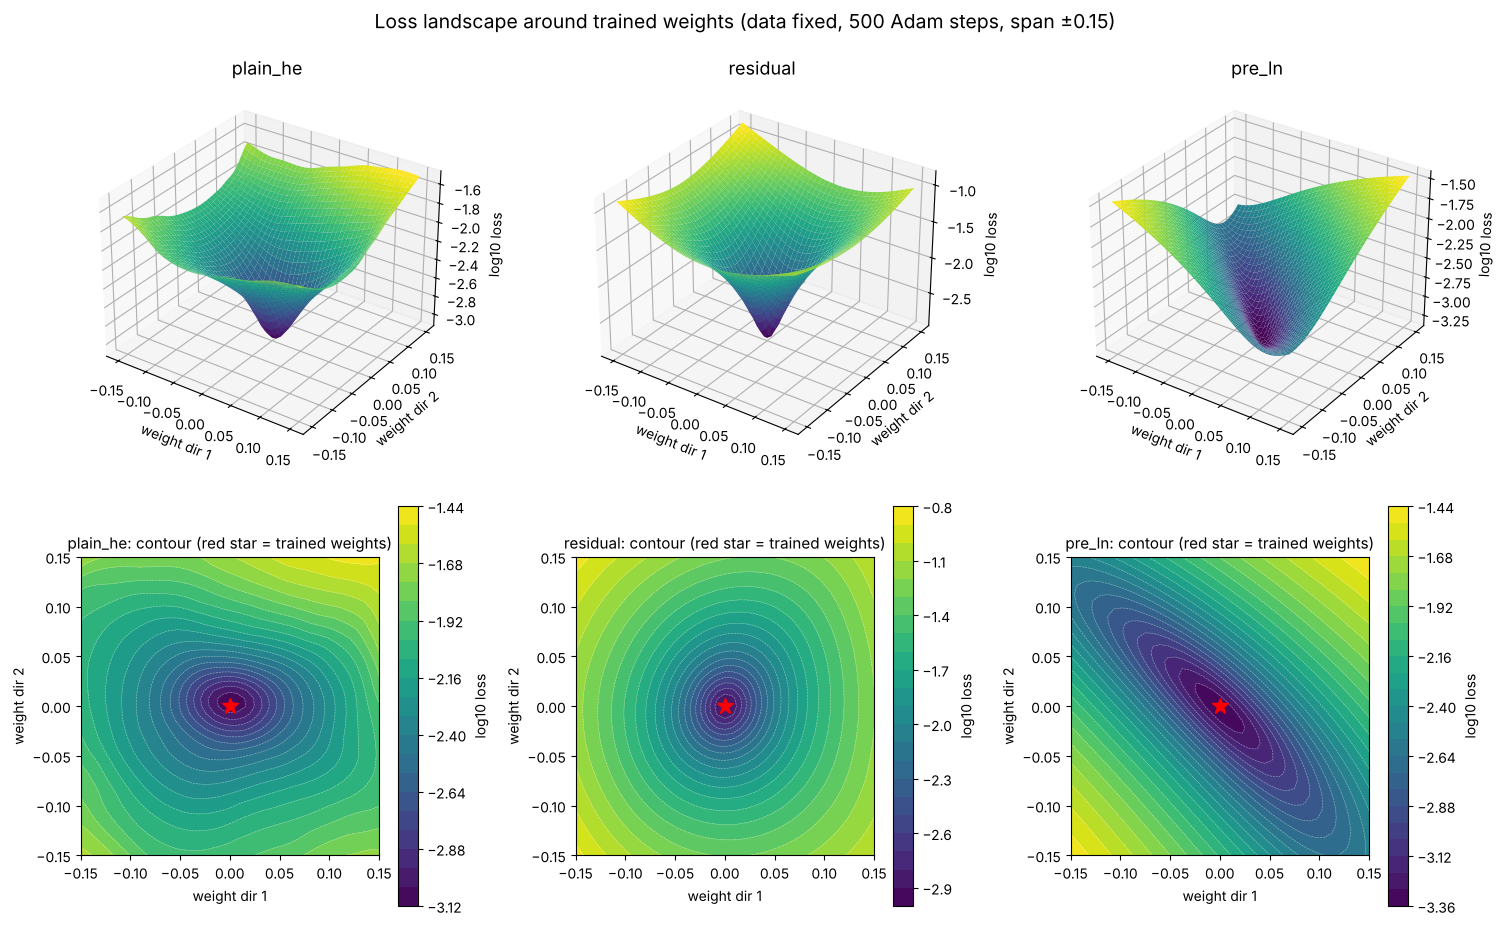

In [11]:
import numpy as np
from torch.func import functional_call


def train_for_landscape(mode, X, Y, steps=500, lr=1e-3):
    torch.manual_seed(0)
    model = Net(mode=mode)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(steps):
        idx = torch.randint(0, len(X), (BATCH,))
        loss = F.mse_loss(model(X[idx]), Y[idx])
        opt.zero_grad()
        loss.backward()
        opt.step()
    return model


def neuron_normalized_direction(params, gen):
    """weight 행렬마다 랜덤 방향을 만들고, 행(뉴런)마다 실제 weight 크기에 맞춘다."""
    d = {}
    for name, p in params.items():
        if p.dim() < 2:                      # bias, LayerNorm → 고정
            d[name] = torch.zeros_like(p)
            continue
        r = torch.randn(p.shape, generator=gen)
        d[name] = r / r.norm(dim=1, keepdim=True) * p.norm(dim=1, keepdim=True)
    return d


def landscape(model, X, Y, span, n=41):
    theta = {k: v.detach().clone() for k, v in model.named_parameters()}
    gen = torch.Generator().manual_seed(123)
    d1 = neuron_normalized_direction(theta, gen)
    d2 = neuron_normalized_direction(theta, gen)
    grid = np.linspace(-span, span, n)
    Z = np.zeros((n, n))
    with torch.no_grad():
        for i, a in enumerate(grid):
            for j, b in enumerate(grid):
                p = {k: theta[k] + a * d1[k] + b * d2[k] for k in theta}
                Z[i, j] = F.mse_loss(functional_call(model, p, (X,)), Y).item()
    return grid, Z


def plot_landscapes(results, span, steps):
    modes = list(results)
    fig = plt.figure(figsize=(15, 9.5))
    for k, mode in enumerate(modes):
        grid, Z = results[mode]
        A, B = np.meshgrid(grid, grid, indexing="ij")
        Zl = np.log10(Z)                     # 구조마다 범위가 크게 달라서 log10
        ax = fig.add_subplot(2, len(modes), k + 1, projection="3d")
        ax.plot_surface(A, B, Zl, cmap="viridis", linewidth=0, antialiased=True)
        ax.set_title(mode, fontsize=13)
        ax.set_xlabel("weight dir 1"); ax.set_ylabel("weight dir 2"); ax.set_zlabel("log10 loss")
        ax.view_init(elev=30, azim=-55)
        ax = fig.add_subplot(2, len(modes), k + 1 + len(modes))
        cs = ax.contourf(A, B, Zl, levels=24, cmap="viridis")
        ax.contour(A, B, Zl, levels=24, colors="white", linewidths=0.4, alpha=0.5)
        ax.plot(0, 0, marker="*", color="red", ms=12)
        fig.colorbar(cs, ax=ax, label="log10 loss")
        ax.set_title(f"{mode}: contour (red star = trained weights)", fontsize=11)
        ax.set_xlabel("weight dir 1"); ax.set_ylabel("weight dir 2")
        ax.set_aspect("equal")
    fig.suptitle(f"Loss landscape around trained weights (data fixed, {steps} Adam steps, span ±{span:g})", fontsize=14)
    plt.tight_layout()
    plt.savefig(f"{OUT}/loss_landscape_span{span:g}.png", dpi=130)
    plt.show()


def part8(modes=("plain_he", "residual", "pre_ln"), spans=(1.0, 0.15), steps=500):
    print("\n=== Part 8. weight 공간 loss 지형 ===")
    torch.manual_seed(0)
    teacher = nn.Sequential(nn.Linear(D, 128), nn.Tanh(), nn.Linear(128, 1))
    X = torch.randn(2048, D)
    with torch.no_grad():
        Y = teacher(X)
    models = {m: train_for_landscape(m, X, Y, steps) for m in modes}
    out = {}
    for span in spans:
        results = {m: landscape(models[m], X, Y, span) for m in modes}
        for m, (grid, Z) in results.items():
            c = len(grid) // 2
            print(f"span ±{span:<5g} {m:9s} 학습된 지점 loss {Z[c, c]:.4f} | 평면 위 최대 {Z.max():.3g} | 중앙값 {np.median(Z):.3g}")
        plot_landscapes(results, span, steps)
        out[span] = {m: Z.tolist() for m, (_, Z) in results.items()}
    return out


r8 = part8()

## 결과 저장

그림은 각 Part에서 `outputs/`에 PNG로 저장됐고, 숫자는 아래 셀이 `outputs/results.json`으로 저장합니다.

In [12]:
with open(f"{OUT}/results.json", "w") as fp:
    json.dump({"part1": r1, "part2_residual": r2, "part2_post_ln": r2b,
               "part3": r3, "part5": r5, "part6": r6}, fp, ensure_ascii=False, indent=1)
print(f"그림과 숫자는 ./{OUT}/ 에 저장되었습니다.")

그림과 숫자는 ./outputs/ 에 저장되었습니다.
